# 🛫 Projet 1 — Prédiction des Retards de Vols
## Partie 1 : Machine Learning

###  Objectif
Construire et comparer plusieurs modèles de Machine Learning afin de prédire les retards des vols à partir des informations disponibles avant le décollage, tout en réalisant un travail complet de préparation et d’analyse des données : nettoyage, exploration, encodage et feature engineering.

Le projet vise à prédire si un vol sera :
- **Classe 0** : À l'heure
- **Classe 1** : Retard de +15 minutes
- **Classe 2** : Retard de +30 minutes

---

## Dataset
Le dataset utilisé provient de Kaggle et est composé de plusieurs fichiers :

- `flights.csv`
- `airlines.csv`
- `airports.csv`

Ces fichiers ont été utilisés pour :
- l’exploration des données,
- le nettoyage,
- le feature engineering,
- et l’encodage des variables.




---

##  Modèles ML implémentés
1. Logistic Regression (baseline)
2. Random Forest
3. SVM (kernel RBF)
4. Gradient Boosting

---

##  Évaluation des modèles
Les performances des modèles seront comparées à l’aide de plusieurs métriques :

- Matrice de confusion
- ROC-AUC
- Courbe Precision-Recall
- Accuracy
- Precision / Recall / F1-score


##**Exploration de la data**

Importation des librairies necessaires

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

flights = pd.read_csv("flights.csv")
airlines = pd.read_csv("airlines.csv")
airports = pd.read_csv("airports.csv")

In [ ]:
print("Flights shape   :", flights.shape)
print("Airlines shape  :", airlines.shape)
print("Airports shape  :", airports.shape)

Flights shape   : (269102, 31)
Airlines shape  : (14, 2)
Airports shape  : (322, 7)


In [ ]:
flights.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,2354.0,-11.0,21.0,15.0,205,194.0,169.0,1448,404.0,4.0,430,408.0,-22.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,2.0,-8.0,12.0,14.0,280,279.0,263.0,2330,737.0,4.0,750,741.0,-9.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,18.0,-2.0,16.0,34.0,286,293.0,266.0,2296,800.0,11.0,806,811.0,5.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,15.0,-5.0,15.0,30.0,285,281.0,258.0,2342,748.0,8.0,805,756.0,-9.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,24.0,-1.0,11.0,35.0,235,215.0,199.0,1448,254.0,5.0,320,259.0,-21.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
airlines.head()



,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways


In [ ]:
airports.head()

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447


In [ ]:
flights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 269102 entries, 0 to 269101
Data columns (total 31 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   YEAR                 269102 non-null  int64  
 1   MONTH                269102 non-null  int64  
 2   DAY                  269102 non-null  int64  
 3   DAY_OF_WEEK          269102 non-null  int64  
 4   AIRLINE              269102 non-null  object 
 5   FLIGHT_NUMBER        269102 non-null  int64  
 6   TAIL_NUMBER          268624 non-null  object 
 7   ORIGIN_AIRPORT       269102 non-null  object 
 8   DESTINATION_AIRPORT  269102 non-null  object 
 9   SCHEDULED_DEPARTURE  269102 non-null  int64  
 10  DEPARTURE_TIME       263809 non-null  float64
 11  DEPARTURE_DELAY      263809 non-null  float64
 12  TAXI_OUT             263641 non-null  float64
 13  WHEELS_OFF           263641 non-null  float64
 14  SCHEDULED_TIME       269102 non-null  int64  
 15  ELAPSED_TIME     

In [ ]:
airlines.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   IATA_CODE  14 non-null     object
 1   AIRLINE    14 non-null     object
dtypes: object(2)
memory usage: 356.0+ bytes


In [ ]:
airports.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   IATA_CODE  322 non-null    object 
 1   AIRPORT    322 non-null    object 
 2   CITY       322 non-null    object 
 3   STATE      322 non-null    object 
 4   COUNTRY    322 non-null    object 
 5   LATITUDE   319 non-null    float64
 6   LONGITUDE  319 non-null    float64
dtypes: float64(2), object(5)
memory usage: 17.7+ KB


### Conclusion de l’exploration initiale des données

L’exploration des datasets a permis d’identifier la structure générale des données ainsi que les principales caractéristiques des variables disponibles.

Le dataset principal `flights.csv` contient près de 269102 vols américains avec 31 variables décrivant :
- les informations temporelles des vols,
- les compagnies aériennes,
- les aéroports,
- les horaires planifiés et réels,
- ainsi que les différents types de retards.

L’analyse des types de données montre la présence :
- de variables numériques (`int64`, `float64`),
- et de variables catégorielles (`object`) nécessitant un encodage pour le Machine Learning.

L’exploration met également en évidence plusieurs colonnes contenant des valeurs manquantes, principalement liées :
- aux vols annulés,
- aux vols déroutés,
- ou aux informations indisponibles après le décollage.

Les fichiers complémentaires `airlines.csv` et `airports.csv` permettront d’enrichir le dataset principal lors de la phase de Feature Engineering grâce aux informations sur :
- les compagnies aériennes,
- les aéroports,
- les villes,
- et la localisation géographique.

Cette première étape valide donc la qualité globale des données et prépare la phase suivante : l’audit détaillé et le nettoyage du dataset.

###Vérification des valeurs manquantes

In [ ]:
missing = flights.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

,0
CANCELLATION_REASON,263575
LATE_AIRCRAFT_DELAY,200455
WEATHER_DELAY,200455
AIRLINE_DELAY,200455
AIR_SYSTEM_DELAY,200455
SECURITY_DELAY,200455
ARRIVAL_DELAY,6148
ELAPSED_TIME,6147
AIR_TIME,6147
WHEELS_ON,5701


###Calcule du pourcentage de NaN

In [ ]:
missing_pct = (flights.isnull().sum() / len(flights)) * 100
missing_pct = missing_pct.sort_values(ascending=False)
missing_pct[missing_pct > 0]

,0
CANCELLATION_REASON,97.946132
LATE_AIRCRAFT_DELAY,74.490342
WEATHER_DELAY,74.490342
AIRLINE_DELAY,74.490342
AIR_SYSTEM_DELAY,74.490342
SECURITY_DELAY,74.490342
ARRIVAL_DELAY,2.284636
ELAPSED_TIME,2.284264
AIR_TIME,2.284264
WHEELS_ON,2.118528


###Vérifier les doublons

In [ ]:
flights.duplicated().sum()

np.int64(0)

aucun doublon → parfait.


Vérification des vols annulés

In [ ]:
flights["CANCELLED"].value_counts()

,count
CANCELLED,
0.0,263574
1.0,5527


Très important car :

un vol annulé n’a pas d’heure réelle
donc beaucoup de NaN sont normaux

##Vérification des vols déroutés

In [ ]:
flights["DIVERTED"].value_counts()

,count
DIVERTED,
0,5803892
1,15187


Même logique :

ces vols ont un comportement atypique
ils peuvent perturber le modèle

##Comprendre la target

In [ ]:
flights["ARRIVAL_DELAY"].describe()



,ARRIVAL_DELAY
count,262954.000000
mean,10.552545
std,43.702992
min,-76.000000
25%,-11.000000
50%,-1.000000
75%,16.000000
max,1593.000000


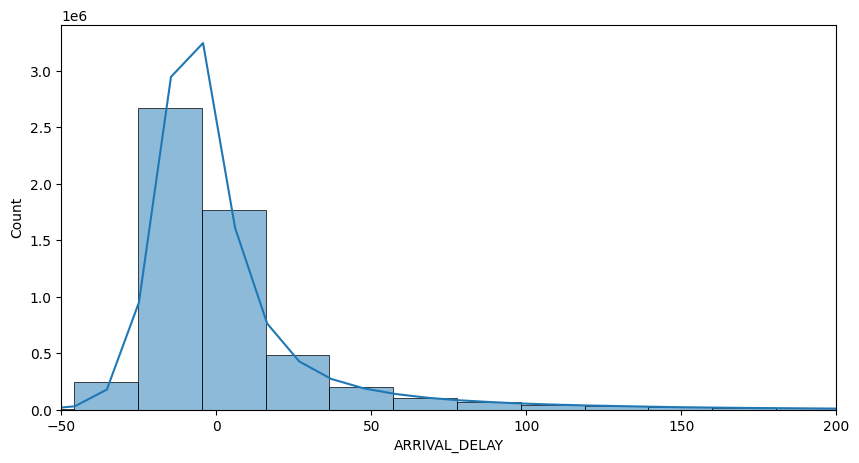

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(flights["ARRIVAL_DELAY"], bins=100, kde=True)
plt.xlim(-50, 200)
plt.show()

Objectif :

voir :

distribution des retards
valeurs extrêmes
asymétrie
outliers

**Analyse de la corrélation des variables numériques**

In [ ]:
numeric_cols = flights.select_dtypes(include=np.number)

corr = numeric_cols.corr()

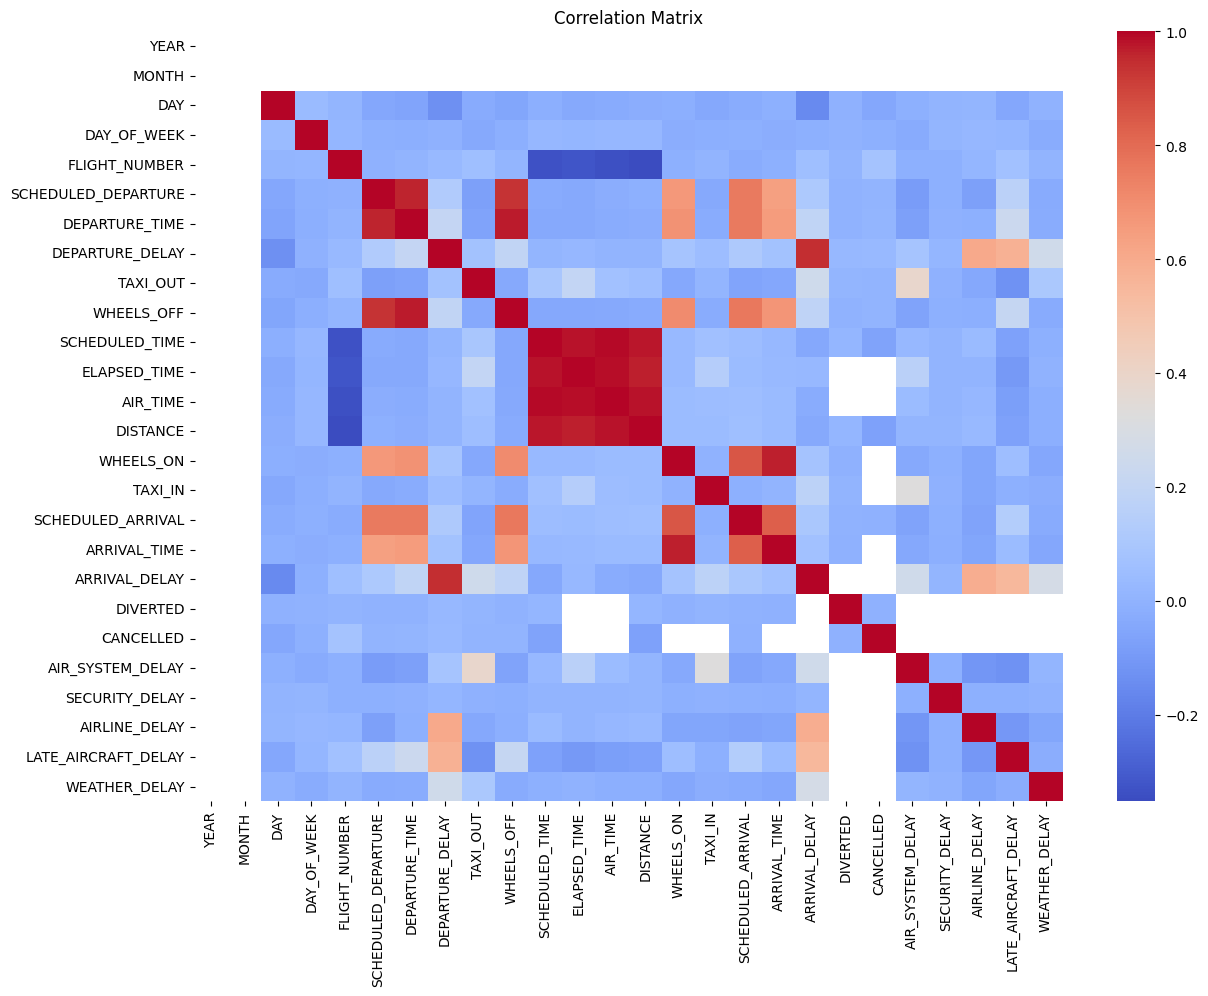

In [ ]:
plt.figure(figsize=(14,10))

sns.heatmap(
    corr,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

Important pour :

détecter relations fortes
comprendre leakage potentiel
voir quelles variables influencent le retard

**Analyse des compagnies aériennes**

In [ ]:
flights["AIRLINE"].value_counts()

,count
AIRLINE,
WN,56962
DL,36394
EV,28763
OO,27774
AA,25344
UA,22121
US,19167
MQ,17106
B6,12475


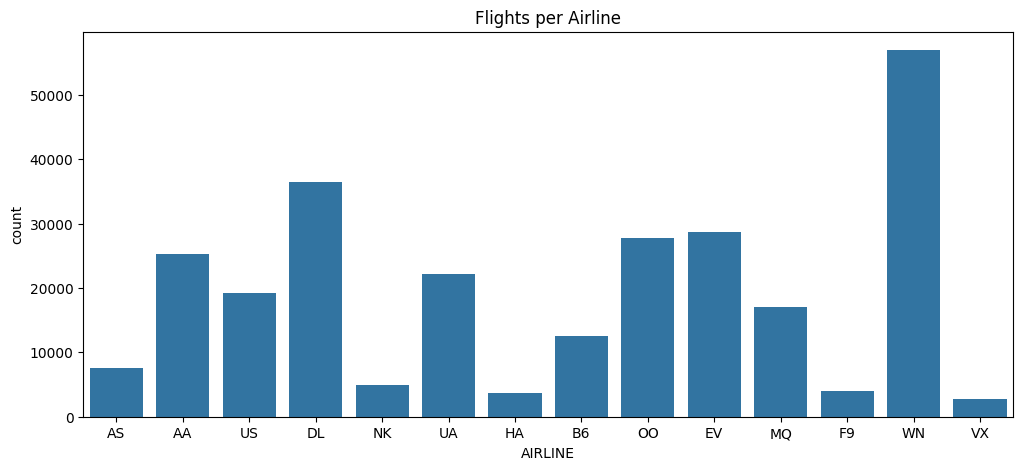

In [ ]:
plt.figure(figsize=(12,5))

sns.countplot(
    x="AIRLINE",
    data=flights
)

plt.title("Flights per Airline")

plt.show()

**Retard moyen par compagnie**

In [ ]:
avg_delay_airline = flights.groupby("AIRLINE")["ARRIVAL_DELAY"].mean()

avg_delay_airline.sort_values()

,ARRIVAL_DELAY
AIRLINE,
AS,0.822328
DL,1.566969
VX,4.068140
HA,4.962650
US,5.383265
WN,8.087393
B6,10.578671
UA,12.320622
AA,12.502933


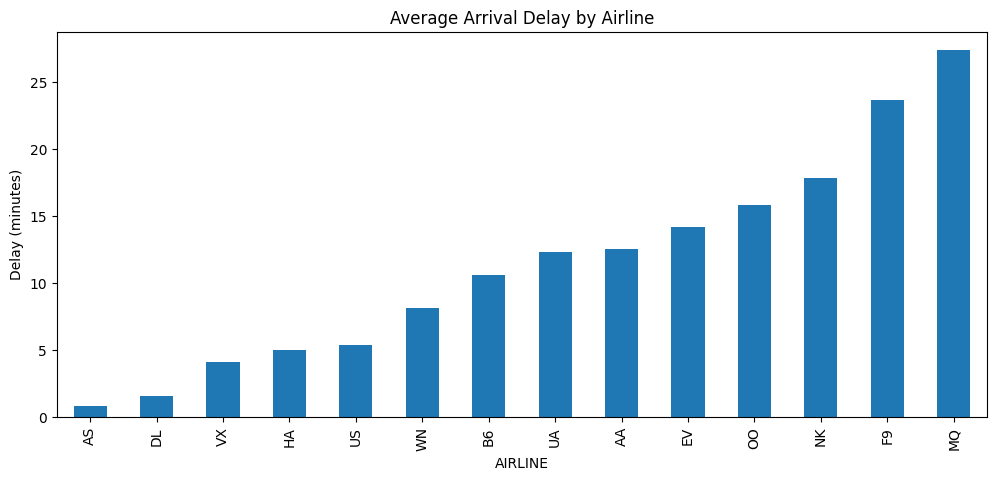

In [ ]:
avg_delay_airline.sort_values().plot(
    kind="bar",
    figsize=(12,5)
)

plt.title("Average Arrival Delay by Airline")

plt.ylabel("Delay (minutes)")

plt.show()

Les performances varient fortement selon la compagnie aérienne.

➡ excellente justification pour utiliser AIRLINE comme feature.

**Analyse des aéroports**

In [ ]:
flights["ORIGIN_AIRPORT"].value_counts().head(10)

,count
ORIGIN_AIRPORT,
ATL,16670
ORD,13375
DFW,13275
LAX,9979
DEN,9939
IAH,7715
PHX,7552
SFO,7454
LAS,6627


In [ ]:
flights["DESTINATION_AIRPORT"].value_counts().head(10)

,count
DESTINATION_AIRPORT,
ATL,16811
ORD,13466
DFW,13376
DEN,9969
LAX,9947
IAH,7750
PHX,7564
SFO,7432
LAS,6608


Aéroports les plus fréquentés

Origines :
- ATL
- ORD
- DFW
- LAX
#####Ces hubs majeurs :

concentrent énormément de trafic
risquent plus de congestion
peuvent générer davantage de retards

**Retard selon jour semaine**

In [ ]:
delay_by_day = flights.groupby("DAY_OF_WEEK")["ARRIVAL_DELAY"].mean()

delay_by_day

,ARRIVAL_DELAY
DAY_OF_WEEK,
1,18.690306
2,12.206315
3,5.551188
4,6.735667
5,7.647515
6,8.746150
7,16.313417


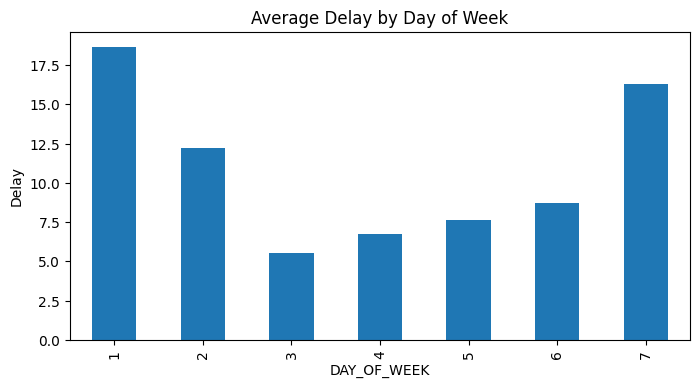

In [ ]:
delay_by_day.plot(
    kind="bar",
    figsize=(8,4)
)

plt.title("Average Delay by Day of Week")

plt.ylabel("Delay")

plt.show()

Interprétation

Le trafic varie selon les jours :

début/fin de semaine → plus chargés
milieu de semaine → plus calme

**Retard selon heure départ**

In [ ]:
flights["DEP_HOUR"] = flights["SCHEDULED_DEPARTURE"] // 100

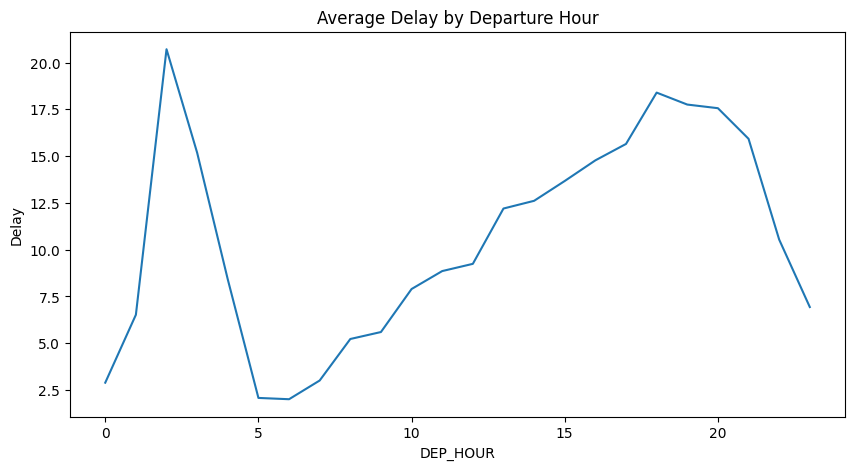

In [ ]:
delay_by_hour = flights.groupby("DEP_HOUR")["ARRIVAL_DELAY"].mean()

delay_by_hour.plot(figsize=(10,5))

plt.title("Average Delay by Departure Hour")

plt.ylabel("Delay")

plt.show()

Les retards s’accumulent au fil de la journée.

C’est un phénomène réel dans l’aviation :

un avion retardé le matin
retarde les vols suivants

##**Data cleaning**

Créer une copie de travail pour eviter de casser la data originale

In [ ]:
df = flights.copy()

In [ ]:
df.shape

(269102, 32)

Suppression des vols annulés et déroutés

*  pas de trajectoire complète
*   valeurs manquantes massives
*  bruit pour le modèle



In [ ]:
df = df[df["CANCELLED"] == 0]
df = df[df["DIVERTED"] == 0]

In [ ]:
df.shape

(262954, 32)

On n a pas perdu trop de lignes

Suppression des colonnes inutiles / fuite de données

In [ ]:
cols_to_drop = [
    "CANCELLATION_REASON",
    "AIR_SYSTEM_DELAY",
    "SECURITY_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "WEATHER_DELAY",
    "WHEELS_OFF",
    "WHEELS_ON",
    "TAXI_IN",
    "TAXI_OUT",
    "DEPARTURE_TIME",
    "ARRIVAL_TIME",
    "ELAPSED_TIME",
    "AIR_TIME"
]

df = df.drop(columns=cols_to_drop)

Ces colonnes :

ne sont connues qu’après le vol
ou expliquent directement le retard
ou causent du data leakage

**Vérifier les NaN restants**

In [ ]:
df.isnull().sum()

,0
YEAR,0
MONTH,0
DAY,0
DAY_OF_WEEK,0
AIRLINE,0
FLIGHT_NUMBER,0
TAIL_NUMBER,0
ORIGIN_AIRPORT,0
DESTINATION_AIRPORT,0
SCHEDULED_DEPARTURE,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

Pas de valeur manquante !

**Supprimer les lignes sans target**

In [ ]:
df = df.dropna(subset=["ARRIVAL_DELAY"])

Suppression de drivted et cancelled car ces colonnes valent maintenant toujours 0
elles n’apportent plus d’information

In [ ]:
df = df.drop(columns=["DIVERTED", "CANCELLED"])

**Vérification structure finale**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 262954 entries, 0 to 269100
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   YEAR                 262954 non-null  int64  
 1   MONTH                262954 non-null  int64  
 2   DAY                  262954 non-null  int64  
 3   DAY_OF_WEEK          262954 non-null  int64  
 4   AIRLINE              262954 non-null  object 
 5   FLIGHT_NUMBER        262954 non-null  int64  
 6   TAIL_NUMBER          262954 non-null  object 
 7   ORIGIN_AIRPORT       262954 non-null  object 
 8   DESTINATION_AIRPORT  262954 non-null  object 
 9   SCHEDULED_DEPARTURE  262954 non-null  int64  
 10  DEPARTURE_DELAY      262954 non-null  float64
 11  SCHEDULED_TIME       262954 non-null  int64  
 12  DISTANCE             262954 non-null  int64  
 13  SCHEDULED_ARRIVAL    262954 non-null  int64  
 14  ARRIVAL_DELAY        262954 non-null  float64
 15  DIVERTED             2

***Traitement des outliers***

Certaines variables numériques contiennent des valeurs extrêmes pouvant perturber l’apprentissage des modèles de Machine Learning, notamment les modèles sensibles aux distributions des données.

Nous appliquons une méthode de capping basée sur l’IQR (Interquartile Range) afin de limiter l’impact des valeurs aberrantes sans supprimer les observations.

In [ ]:
numeric_cols = [
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY",
    "DISTANCE",
    "SCHEDULED_TIME"
]
df[numeric_cols].describe()

,DEPARTURE_DELAY,ARRIVAL_DELAY,DISTANCE,SCHEDULED_TIME
count,262954.000000,262954.000000,262954.000000,262954.000000
mean,13.698381,10.552545,815.579866,141.598527
std,40.643242,43.702992,601.279453,75.405223
min,-42.000000,-76.000000,31.000000,23.000000
25%,-4.000000,-11.000000,370.000000,85.000000
50%,0.000000,-1.000000,650.000000,123.000000
75%,14.000000,16.000000,1056.000000,175.000000
max,1604.000000,1593.000000,4983.000000,718.000000


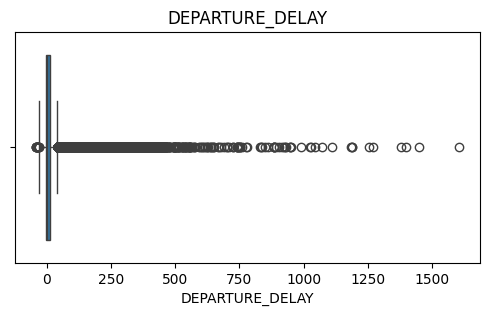

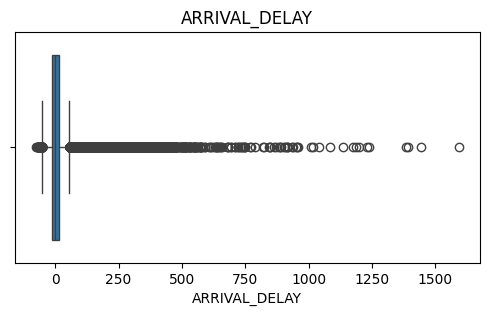

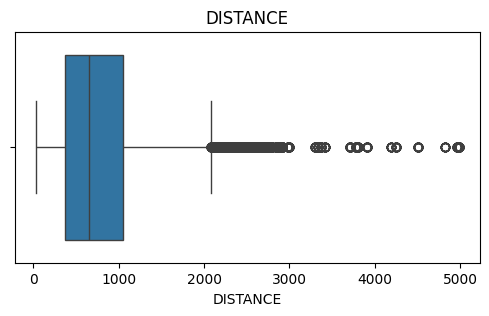

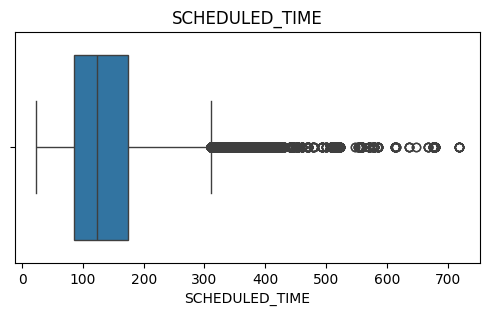

In [ ]:
for col in numeric_cols:

    plt.figure(figsize=(6,3))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

ARRIVAL_DELAY max = 1593 min
DEPARTURE_DELAY max = 1604 min

→ ce sont des retards énormes et rares qui peuvent perturber le modèle.

In [ ]:

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower, lower, df[col])
    df[col] = np.where(df[col] > upper, upper, df[col])

Verification

In [ ]:
df[numeric_cols].describe()

,DEPARTURE_DELAY,ARRIVAL_DELAY,DISTANCE,SCHEDULED_TIME
count,262954.000000,262954.000000,262954.000000,262954.000000
mean,7.108422,5.252791,793.151141,139.408767
std,16.383759,23.512184,536.969885,68.901323
min,-31.000000,-51.500000,31.000000,23.000000
25%,-4.000000,-11.000000,370.000000,85.000000
50%,0.000000,-1.000000,650.000000,123.000000
75%,14.000000,16.000000,1056.000000,175.000000
max,41.000000,56.500000,2085.000000,310.000000


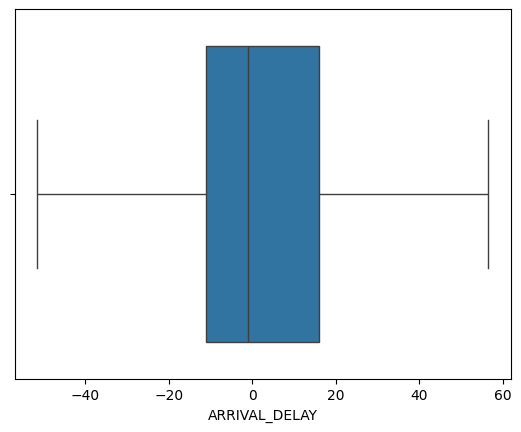

In [ ]:
sns.boxplot(x=df["ARRIVAL_DELAY"])
plt.show()

**Verification des types avant de passer au feature engineering **

In [ ]:
df.dtypes

,0
YEAR,int64
MONTH,int64
DAY,int64
DAY_OF_WEEK,int64
AIRLINE,object
FLIGHT_NUMBER,int64
TAIL_NUMBER,object
ORIGIN_AIRPORT,object
DESTINATION_AIRPORT,object
SCHEDULED_DEPARTURE,int64


***Création de la target classification***

In [ ]:
def categorize_delay(x):
    if x <= 15:
        return 0
    elif x <= 30:
        return 1
    else:
        return 2

df["DELAY_CLASS"] = df["ARRIVAL_DELAY"].apply(categorize_delay)

Transformation de la variable cible en classification multi-classes
- 0 : vol à l'heure ou léger retard
- 1 : retard modéré
- 2 : retard important
- Cela permet d'adapter le problème aux modèles de classification.

***Vérification finale***

In [ ]:
df.shape

(262954, 17)

##**FEATURE ENGINEERING**

Creation d'une copie du dataset propre

In [ ]:
df_fe = df.copy()

**Creation de l' Heure de départ / arrivée**

In [ ]:
df_fe["DEP_HOUR"] = df_fe["SCHEDULED_DEPARTURE"] // 100
df_fe["ARR_HOUR"] = df_fe["SCHEDULED_ARRIVAL"] // 100

***Création des périodes de la journée***

In [ ]:
def get_period(hour):

    if hour < 6:
        return "night"

    elif hour < 12:
        return "morning"

    elif hour < 18:
        return "afternoon"

    else:
        return "evening"

df_fe["DAY_PERIOD"] = df_fe["DEP_HOUR"].apply(get_period)

***Période de l’année (SAISON)***

In [ ]:
def get_season(month):

    if month in [12, 1, 2]:
        return "winter"

    elif month in [3, 4, 5]:
        return "spring"

    elif month in [6, 7, 8]:
        return "summer"

    else:
        return "autumn"

df_fe["SEASON"] = df_fe["MONTH"].apply(get_season)

***CONGESTION AÉROPORT***

In [ ]:
airport_traffic = df_fe["ORIGIN_AIRPORT"].value_counts()

df_fe["AIRPORT_TRAFFIC"] = df_fe["ORIGIN_AIRPORT"].map(airport_traffic)

##### Estimation simplifiée de la congestion des aéroports
##### basée sur le nombre de vols au départ de chaque aéroport.

**Météo**

In [ ]:
def weather_risk(season):

    if season == "winter":
        return "high"

    elif season == "summer":
        return "medium"

    else:
        return "low"

df_fe["WEATHER_RISK"] = df_fe["SEASON"].apply(weather_risk)

on fait une approximation intelligente basée sur :

- saison
- retard météo existant dans les données originales

**Week-end**

In [ ]:
df_fe["IS_WEEKEND"] = df_fe["DAY_OF_WEEK"].apply(
    lambda x: 1 if x in [6, 7] else 0
)

le modèle peut apprendre qu’un vol un samedi/dimanche n’a pas le même comportement qu’un lundi.

***Vérification***

In [ ]:
df_fe.shape

(262954, 23)

In [ ]:
df_fe.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DEP_HOUR,DELAY_CLASS,ARR_HOUR,DAY_PERIOD,SEASON,AIRPORT_TRAFFIC,WEATHER_RISK,IS_WEEKEND
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,-11.0,205.0,1448.0,430,-22.0,0,0,4,night,winter,691,high,0
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,-8.0,280.0,2085.0,750,-9.0,0,0,7,night,winter,9861,high,0
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,-2.0,286.0,2085.0,806,5.0,0,0,8,night,winter,7310,high,0
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,-5.0,285.0,2085.0,805,-9.0,0,0,8,night,winter,9861,high,0
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,-1.0,235.0,1448.0,320,-21.0,0,0,3,night,winter,4863,high,0


####***Merge AIRLINES***

In [ ]:
df_fe = df_fe.merge(
    airlines,
    left_on="AIRLINE",
    right_on="IATA_CODE",
    how="left"
)

In [ ]:
df_fe.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE_x,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DEP_HOUR,DELAY_CLASS,ARR_HOUR,DAY_PERIOD,SEASON,AIRPORT_TRAFFIC,WEATHER_RISK,IS_WEEKEND,IATA_CODE,AIRLINE_y
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,-11.0,205.0,1448.0,430,-22.0,0,0,4,night,winter,691,high,0,AS,Alaska Airlines Inc.
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,-8.0,280.0,2085.0,750,-9.0,0,0,7,night,winter,9861,high,0,AA,American Airlines Inc.
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,-2.0,286.0,2085.0,806,5.0,0,0,8,night,winter,7310,high,0,US,US Airways Inc.
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,-5.0,285.0,2085.0,805,-9.0,0,0,8,night,winter,9861,high,0,AA,American Airlines Inc.
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,-1.0,235.0,1448.0,320,-21.0,0,0,3,night,winter,4863,high,0,AS,Alaska Airlines Inc.


In [ ]:
df_fe = df_fe.drop(columns=["IATA_CODE"])

df_fe = df_fe.rename(
    columns={"AIRLINE_y": "AIRLINE_NAME"}
)

In [ ]:
df_fe = df_fe.rename(
    columns={"AIRLINE_x": "AIRLINE"}
)

In [ ]:
df_fe.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DEP_HOUR,DELAY_CLASS,ARR_HOUR,DAY_PERIOD,SEASON,AIRPORT_TRAFFIC,WEATHER_RISK,IS_WEEKEND,AIRLINE_NAME
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,-11.0,205.0,1448.0,430,-22.0,0,0,4,night,winter,691,high,0,Alaska Airlines Inc.
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,-8.0,280.0,2085.0,750,-9.0,0,0,7,night,winter,9861,high,0,American Airlines Inc.
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,-2.0,286.0,2085.0,806,5.0,0,0,8,night,winter,7310,high,0,US Airways Inc.
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,-5.0,285.0,2085.0,805,-9.0,0,0,8,night,winter,9861,high,0,American Airlines Inc.
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,-1.0,235.0,1448.0,320,-21.0,0,0,3,night,winter,4863,high,0,Alaska Airlines Inc.


####***Merge AIRPORTS***

In [ ]:
df_fe = df_fe.merge(
    airports,
    left_on="ORIGIN_AIRPORT",
    right_on="IATA_CODE",
    how="left"
)

In [ ]:
df_fe = df_fe.drop(columns=["IATA_CODE"])

In [ ]:
df_fe.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DEP_HOUR,DELAY_CLASS,ARR_HOUR,DAY_PERIOD,SEASON,AIRPORT_TRAFFIC,WEATHER_RISK,IS_WEEKEND,AIRLINE_NAME,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,-11.0,205.0,1448.0,430,-22.0,0,0,4,night,winter,691,high,0,Alaska Airlines Inc.,Ted Stevens Anchorage International Airport,Anchorage,AK,USA,61.17432,-149.99619
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,-8.0,280.0,2085.0,750,-9.0,0,0,7,night,winter,9861,high,0,American Airlines Inc.,Los Angeles International Airport,Los Angeles,CA,USA,33.94254,-118.40807
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,-2.0,286.0,2085.0,806,5.0,0,0,8,night,winter,7310,high,0,US Airways Inc.,San Francisco International Airport,San Francisco,CA,USA,37.61900,-122.37484
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,-5.0,285.0,2085.0,805,-9.0,0,0,8,night,winter,9861,high,0,American Airlines Inc.,Los Angeles International Airport,Los Angeles,CA,USA,33.94254,-118.40807
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,-1.0,235.0,1448.0,320,-21.0,0,0,3,night,winter,4863,high,0,Alaska Airlines Inc.,Seattle-Tacoma International Airport,Seattle,WA,USA,47.44898,-122.30931


In [ ]:
cols_to_drop = [
    "AIRLINE_NAME",
    "AIRPORT",
    "CITY",
    "STATE",
    "COUNTRY",
    "TAIL_NUMBER"
]

df_fe = df_fe.drop(columns=cols_to_drop)

Sppression de Colonnes probablement inutiles pour le modèle

***Vérification finale***

In [ ]:
df_fe.shape

(262954, 24)

##**Encodage**

**Encodage compagnie aérienne**
#####One-Hot Encoding

In [ ]:
df_fe = pd.get_dummies(
    df_fe,
    columns=["AIRLINE"],
    drop_first=True
)

**Encodage aéroport origine/destination**
#####Frequency Encoding

In [ ]:
origin_freq = df_fe["ORIGIN_AIRPORT"].value_counts()

df_fe["ORIGIN_AIRPORT_FREQ"] = df_fe["ORIGIN_AIRPORT"].map(origin_freq)

In [ ]:
dest_freq = df_fe["DESTINATION_AIRPORT"].value_counts()

df_fe["DESTINATION_AIRPORT_FREQ"] = df_fe["DESTINATION_AIRPORT"].map(dest_freq)

**suppression des colonnes texte**

In [ ]:
df_fe = df_fe.drop(columns=[
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT"
])

**encodage de la période**

In [ ]:
df_fe = pd.get_dummies(
    df_fe,
    columns=["DAY_PERIOD"],
    drop_first=True
)

**Encodage Saison**

In [ ]:
df_fe = pd.get_dummies(
    df_fe,
    columns=["SEASON"],
    drop_first=True
)

**Encodage Météo**

In [ ]:
df_fe = pd.get_dummies(
    df_fe,
    columns=["WEATHER_RISK"],
    drop_first=True
)

In [ ]:
df_fe.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_NUMBER,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DEP_HOUR,DELAY_CLASS,ARR_HOUR,AIRPORT_TRAFFIC,IS_WEEKEND,LATITUDE,LONGITUDE,AIRLINE_AS,AIRLINE_B6,AIRLINE_DL,AIRLINE_EV,AIRLINE_F9,AIRLINE_HA,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN,DAY_PERIOD_evening,DAY_PERIOD_morning,DAY_PERIOD_night
0,2015,1,1,4,98,5,-11.0,205.0,1448.0,430,-22.0,0,0,4,691,0,61.17432,-149.99619,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,2015,1,1,4,2336,10,-8.0,280.0,2085.0,750,-9.0,0,0,7,9861,0,33.94254,-118.40807,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2,2015,1,1,4,840,20,-2.0,286.0,2085.0,806,5.0,0,0,8,7310,0,37.61900,-122.37484,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True
3,2015,1,1,4,258,20,-5.0,285.0,2085.0,805,-9.0,0,0,8,9861,0,33.94254,-118.40807,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4,2015,1,1,4,135,25,-1.0,235.0,1448.0,320,-21.0,0,0,3,4863,0,47.44898,-122.30931,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True


In [ ]:
df_fe = df_fe.drop(columns=["ARRIVAL_DELAY"])

In [ ]:
df_fe.shape

(262954, 33)

In [ ]:
df_fe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262954 entries, 0 to 262953
Data columns (total 33 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   YEAR                 262954 non-null  int64  
 1   MONTH                262954 non-null  int64  
 2   DAY                  262954 non-null  int64  
 3   DAY_OF_WEEK          262954 non-null  int64  
 4   FLIGHT_NUMBER        262954 non-null  int64  
 5   SCHEDULED_DEPARTURE  262954 non-null  int64  
 6   DEPARTURE_DELAY      262954 non-null  float64
 7   SCHEDULED_TIME       262954 non-null  float64
 8   DISTANCE             262954 non-null  float64
 9   SCHEDULED_ARRIVAL    262954 non-null  int64  
 10  DEP_HOUR             262954 non-null  int64  
 11  DELAY_CLASS          262954 non-null  int64  
 12  ARR_HOUR             262954 non-null  int64  
 13  AIRPORT_TRAFFIC      262954 non-null  int64  
 14  IS_WEEKEND           262954 non-null  int64  
 15  LATITUDE         

In [ ]:
df_fe = df_fe.dropna()

In [ ]:
bool_cols = df_fe.select_dtypes(include="bool").columns

df_fe[bool_cols] = df_fe[bool_cols].astype(int)

In [ ]:
df_fe.info()

<class 'pandas.core.frame.DataFrame'>
Index: 262793 entries, 0 to 262953
Data columns (total 33 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   YEAR                 262793 non-null  int64  
 1   MONTH                262793 non-null  int64  
 2   DAY                  262793 non-null  int64  
 3   DAY_OF_WEEK          262793 non-null  int64  
 4   FLIGHT_NUMBER        262793 non-null  int64  
 5   SCHEDULED_DEPARTURE  262793 non-null  int64  
 6   DEPARTURE_DELAY      262793 non-null  float64
 7   SCHEDULED_TIME       262793 non-null  float64
 8   DISTANCE             262793 non-null  float64
 9   SCHEDULED_ARRIVAL    262793 non-null  int64  
 10  DEP_HOUR             262793 non-null  int64  
 11  DELAY_CLASS          262793 non-null  int64  
 12  ARR_HOUR             262793 non-null  int64  
 13  AIRPORT_TRAFFIC      262793 non-null  int64  
 14  IS_WEEKEND           262793 non-null  int64  
 15  LATITUDE             2

In [ ]:
df_fe.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_NUMBER,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,DEP_HOUR,DELAY_CLASS,ARR_HOUR,AIRPORT_TRAFFIC,IS_WEEKEND,LATITUDE,LONGITUDE,AIRLINE_AS,AIRLINE_B6,AIRLINE_DL,AIRLINE_EV,AIRLINE_F9,AIRLINE_HA,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN,DAY_PERIOD_evening,DAY_PERIOD_morning,DAY_PERIOD_night
0,2015,1,1,4,98,5,-11.0,205.0,1448.0,430,0,0,4,691,0,61.17432,-149.99619,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,2015,1,1,4,2336,10,-8.0,280.0,2085.0,750,0,0,7,9861,0,33.94254,-118.40807,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,2015,1,1,4,840,20,-2.0,286.0,2085.0,806,0,0,8,7310,0,37.61900,-122.37484,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,2015,1,1,4,258,20,-5.0,285.0,2085.0,805,0,0,8,9861,0,33.94254,-118.40807,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4,2015,1,1,4,135,25,-1.0,235.0,1448.0,320,0,0,3,4863,0,47.44898,-122.30931,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


##**Sauvegarder le dataset final**

In [ ]:
df_fe.to_csv("flights_cleaned_encoded.csv", index=False)

# **Machine Learning Models**

In [ ]:
!pip install xgboost

## 1. Importation des librairies

On importe toutes les librairies nécessaires :
- **pandas / numpy** : manipulation des données
- **matplotlib / seaborn** : visualisation
- **sklearn** : modèles ML et métriques d'évaluation
- **xgboost** : algorithme Gradient Boosting optimisé

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

print(" Tout importé avec succès")

 Tout importé avec succès


In [ ]:
import joblib

print(" Session active")

 Session active


## 2. Chargement et exploration des données

On charge le fichier produit par le Binôme 1 (flights_cleaned_encoded.csv).
Ce fichier contient les données déjà nettoyées, encodées et enrichies avec
des features comme IS_WEEKEND, DAY_PERIOD, AIRPORT_TRAFFIC, etc.

On vérifie la distribution de la variable cible DELAY_CLASS pour détecter
un éventuel déséquilibre des classes.

In [ ]:
df = pd.read_csv("flights_cleaned_encoded.csv")

print(" Shape:", df.shape)
print("\n Distribution DELAY_CLASS:")
print(df['DELAY_CLASS'].value_counts())

df.head()

 Shape: (262793, 33)

 Distribution DELAY_CLASS:
DELAY_CLASS
0    196459
2     42329
1     24005
Name: count, dtype: int64


,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_NUMBER,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,...,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN,DAY_PERIOD_evening,DAY_PERIOD_morning,DAY_PERIOD_night
0,2015,1,1,4,98,5,-11.0,205.0,1448.0,430,...,0,0,0,0,0,0,0,0,0,1
1,2015,1,1,4,2336,10,-8.0,280.0,2085.0,750,...,0,0,0,0,0,0,0,0,0,1
2,2015,1,1,4,840,20,-2.0,286.0,2085.0,806,...,0,0,0,0,1,0,0,0,0,1
3,2015,1,1,4,258,20,-5.0,285.0,2085.0,805,...,0,0,0,0,0,0,0,0,0,1
4,2015,1,1,4,135,25,-1.0,235.0,1448.0,320,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
y = df['DELAY_CLASS']
X = df.drop(columns=['DELAY_CLASS'])

print(" Target (y) :", y.shape)
print(" Features (X) :", X.shape)
print("\nFeatures utilisées :")
print(X.columns.tolist())

 Target (y) : (262793,)
 Features (X) : (262793, 32)

Features utilisées :
['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'FLIGHT_NUMBER', 'SCHEDULED_DEPARTURE', 'DEPARTURE_DELAY', 'SCHEDULED_TIME', 'DISTANCE', 'SCHEDULED_ARRIVAL', 'DEP_HOUR', 'ARR_HOUR', 'AIRPORT_TRAFFIC', 'IS_WEEKEND', 'LATITUDE', 'LONGITUDE', 'AIRLINE_AS', 'AIRLINE_B6', 'AIRLINE_DL', 'AIRLINE_EV', 'AIRLINE_F9', 'AIRLINE_HA', 'AIRLINE_MQ', 'AIRLINE_NK', 'AIRLINE_OO', 'AIRLINE_UA', 'AIRLINE_US', 'AIRLINE_VX', 'AIRLINE_WN', 'DAY_PERIOD_evening', 'DAY_PERIOD_morning', 'DAY_PERIOD_night']


## 3. Séparation des features et de la target

On sépare :
- **X** : les 32 features (variables explicatives)
- **y** : DELAY_CLASS (variable cible à prédire)

Puis on divise en **80% train / 20% test** avec stratify=y pour conserver
les proportions de chaque classe dans les deux ensembles.

In [ ]:
nan_rows = y.isnull()
if nan_rows.any():
    print(f" Detected {nan_rows.sum()} NaN values in the target variable 'y'. Removing corresponding rows from X and y.")
    X = X[~nan_rows]
    y = y[~nan_rows]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(" Split effectué :")
print(f"   Train : {X_train.shape[0]} vols ({X_train.shape[0]/len(X)*100:.0f}%")
print(f"   Test  : {X_test.shape[0]} vols ({X_test.shape[0]/len(X)*100:.0f}%")
print(f"\nDistribution classes dans le train :")
print(y_train.value_counts())

 Split effectué :
   Train : 210234 vols (80%
   Test  : 52559 vols (20%

Distribution classes dans le train :
DELAY_CLASS
0    157167
2     33863
1     19204
Name: count, dtype: int64


## 4. Normalisation des données

On applique un StandardScaler pour mettre toutes les features à la même échelle
(moyenne=0, écart-type=1).

⚠️ Règle importante : on applique fit_transform uniquement sur le train,
et transform sur le test. Faire autrement causerait un data leakage
(le modèle verrait des informations du test pendant l'entraînement).

Note : Random Forest et XGBoost n'ont pas besoin de normalisation.
Le scaling est utilisé uniquement pour Logistic Regression et SVM.

In [ ]:
scaler = StandardScaler()

# fit UNIQUEMENT sur le train, jamais sur le test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(" Normalisation effectuée")
print(f"Moyenne après scaling (doit être ≈ 0) : {X_train_scaled[:, 0].mean():.4f}")
print(f"Écart-type après scaling (doit être ≈ 1) : {X_train_scaled[:, 0].std():.4f}")

 Normalisation effectuée
Moyenne après scaling (doit être ≈ 0) : 0.0000
Écart-type après scaling (doit être ≈ 1) : 0.0000


In [ ]:
results = {}

def evaluate_model(name, model, X_test, y_test, use_proba=True):

    y_pred = model.predict(X_test)

    # 1. Classification Report
    print(f"\n{'='*55}")
    print(f" MODÈLE : {name}")
    print('='*55)
    print(classification_report(
        y_test, y_pred,
        target_names=["À l'heure", "Retard +15min", "Retard +30min"]
    ))

    # 2. Matrice de confusion
    fig, ax = plt.subplots(figsize=(6, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["À l'heure", "+15min", "+30min"],
        cmap='Blues', ax=ax
    )
    ax.set_title(f"Matrice de Confusion — {name}")
    plt.tight_layout()
    plt.show()

    # 3. ROC-AUC
    if use_proba:
        y_proba = model.predict_proba(X_test)
        y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
        auc = roc_auc_score(y_test_bin, y_proba, multi_class='ovr')
    else:
        auc = 0

    # 4. Faux négatifs (retards non détectés)
    false_negatives = ((y_pred == 0) & (y_test != 0)).sum()
    total_delays = (y_test != 0).sum()
    fn_rate = false_negatives / total_delays * 100

    print(f" Faux négatifs (retards non anticipés) : {false_negatives} / {total_delays} ({fn_rate:.1f}%)")
    print(f" ROC-AUC : {auc:.4f}")

    # Stocker
    results[name] = {
        'Accuracy': round((y_pred == y_test).mean(), 4),
        'ROC-AUC': round(auc, 4),
        'Faux Négatifs': false_negatives,
        'Taux FN %': round(fn_rate, 1)
    }

print(" Fonction d'évaluation prête")

 Fonction d'évaluation prête


## 5. Modèle 1 — Logistic Regression (Baseline)

La Logistic Regression est le modèle le plus simple. Elle trace une frontière
linéaire entre les classes. On l'utilise comme baseline : tous les autres
modèles doivent faire mieux qu'elle.

On utilise class_weight='balanced' pour compenser le déséquilibre des classes
(la classe 1 représente seulement 9% des données).

Résultats obtenus :
- Accuracy : 0.82
- ROC-AUC : 0.895
- Faux négatifs : 11.5% (le plus bas de tous les modèles)

 Entraînement Logistic Regression...
 Entraînement terminé !

 MODÈLE : Logistic Regression
               precision    recall  f1-score   support

    À l'heure       0.96      0.85      0.90     39292
Retard +15min       0.27      0.52      0.36      4801
Retard +30min       0.82      0.84      0.83      8466

     accuracy                           0.82     52559
    macro avg       0.68      0.74      0.70     52559
 weighted avg       0.87      0.82      0.84     52559



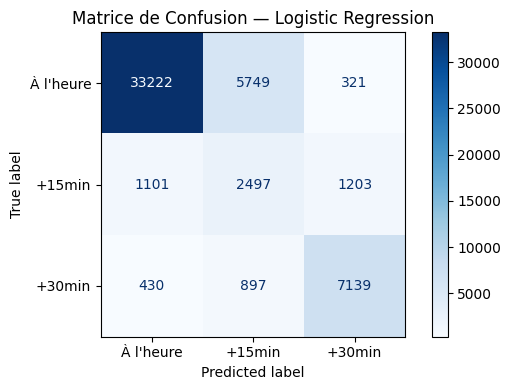

 Faux négatifs (retards non anticipés) : 1531 / 13267 (11.5%)
 ROC-AUC : 0.8950


In [ ]:
print(" Entraînement Logistic Regression...")

lr = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)
lr.fit(X_train_scaled, y_train)

print(" Entraînement terminé !")
evaluate_model("Logistic Regression", lr, X_test_scaled, y_test)

## 6. Modèle 2 — Random Forest

Le Random Forest construit 100 arbres de décision en parallèle (n_jobs=-1
utilise tous les CPU disponibles). Chaque arbre vote et la majorité gagne.
Il capture des relations non-linéaires entre les variables.

On analyse également les feature importances pour comprendre quelles variables
influencent le plus les prédictions.

Résultats obtenus :
- Accuracy : 0.89 (meilleure que LR )
- ROC-AUC : 0.922 (meilleure que LR )
- DEPARTURE_DELAY représente 44% de l'importance totale

 Entraînement Random Forest (2-3 min)...
 Entraînement terminé !

 MODÈLE : Random Forest
               precision    recall  f1-score   support

    À l'heure       0.90      0.99      0.94     39292
Retard +15min       0.53      0.19      0.28      4801
Retard +30min       0.89      0.81      0.85      8466

     accuracy                           0.89     52559
    macro avg       0.77      0.66      0.69     52559
 weighted avg       0.86      0.89      0.87     52559



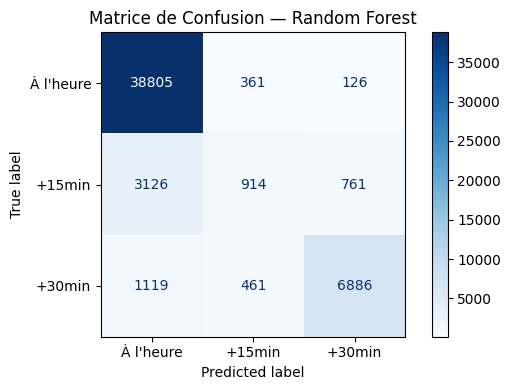

 Faux négatifs (retards non anticipés) : 4245 / 13267 (32.0%)
 ROC-AUC : 0.9220


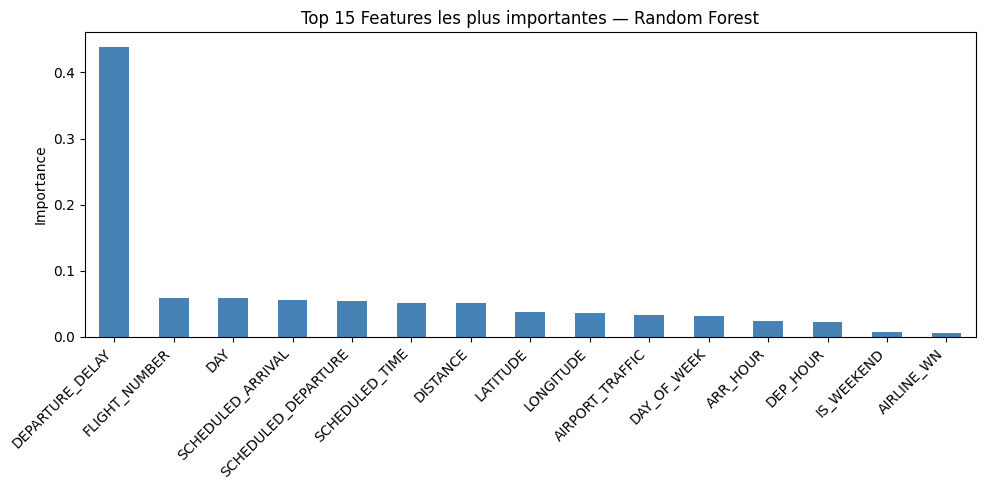


Top 5 features :
DEPARTURE_DELAY        0.438851
FLIGHT_NUMBER          0.058853
DAY                    0.058462
SCHEDULED_ARRIVAL      0.056102
SCHEDULED_DEPARTURE    0.053367
dtype: float64


In [ ]:
print(" Entraînement Random Forest (2-3 min)...")

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)
rf.fit(X_train, y_train)

print(" Entraînement terminé !")
evaluate_model("Random Forest", rf, X_test, y_test)

# Feature importances
feat_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feat_imp.head(15).plot(kind='bar', color='steelblue')
plt.title("Top 15 Features les plus importantes — Random Forest")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nTop 5 features :")
print(feat_imp.head())

## 7. Modèle 3 — SVM (kernel RBF)

Le SVM cherche la meilleure frontière mathématique entre les classes.
Le kernel RBF lui permet de gérer des séparations non-linéaires.

 Contrainte : SVM est très lent sur de grandes données.
On sous-échantillonne à 15 000 lignes pour l'entraînement,
mais on évalue sur les 52 559 lignes de test complètes.

Résultats obtenus :
- Accuracy : 0.83
- ROC-AUC : 0.908
- Faux négatifs : 14.1%

 Entraînement SVM sur sous-échantillon...
(SVM est trop lent sur 200k lignes → on prend 15 000 lignes)
Taille sous-échantillon SVM : 15000 lignes
 Entraînement terminé !

 MODÈLE : SVM (RBF)
               precision    recall  f1-score   support

    À l'heure       0.95      0.87      0.91     39292
Retard +15min       0.30      0.53      0.38      4801
Retard +30min       0.86      0.81      0.83      8466

     accuracy                           0.83     52559
    macro avg       0.70      0.74      0.71     52559
 weighted avg       0.88      0.83      0.85     52559



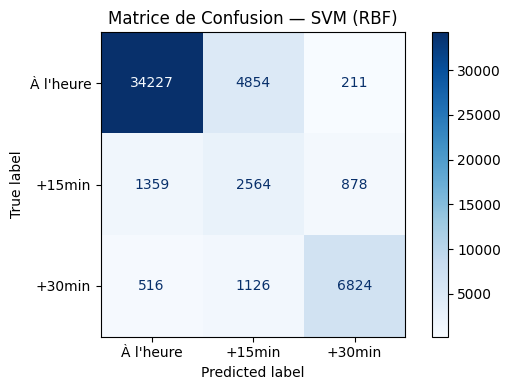

 Faux négatifs (retards non anticipés) : 1875 / 13267 (14.1%)
 ROC-AUC : 0.9078

 Note : SVM entraîné sur 15 000 lignes uniquement (contrainte de performance)


In [ ]:
print(" Entraînement SVM sur sous-échantillon...")
print("(SVM est trop lent sur 200k lignes → on prend 15 000 lignes)")

X_svm_train, _, y_svm_train, _ = train_test_split(
    X_train_scaled, y_train,
    train_size=15000,
    random_state=42,
    stratify=y_train
)

print(f"Taille sous-échantillon SVM : {X_svm_train.shape[0]} lignes")

svm = SVC(
    kernel='rbf',
    probability=True,
    random_state=42,
    class_weight='balanced'
)
svm.fit(X_svm_train, y_svm_train)

print(" Entraînement terminé !")
evaluate_model("SVM (RBF)", svm, X_test_scaled, y_test)

print("\n Note : SVM entraîné sur 15 000 lignes uniquement (contrainte de performance)")

## 8. Modèle 4 — XGBoost (Gradient Boosting)

XGBoost construit des arbres séquentiellement : chaque nouvel arbre corrige
les erreurs du précédent. C'est différent du Random Forest qui construit
tous les arbres indépendamment.

XGBoost est reconnu comme l'un des algorithmes les plus performants
sur les données tabulaires.

Résultats obtenus :
- Accuracy : 0.89
- ROC-AUC : 0.931 (meilleur de tous les modèles )
- Faux négatifs : 25.9%

 Entraînement XGBoost...
 Entraînement terminé !

 MODÈLE : XGBoost
               precision    recall  f1-score   support

    À l'heure       0.92      0.98      0.95     39292
Retard +15min       0.53      0.30      0.38      4801
Retard +30min       0.88      0.82      0.85      8466

     accuracy                           0.89     52559
    macro avg       0.78      0.70      0.73     52559
 weighted avg       0.88      0.89      0.88     52559



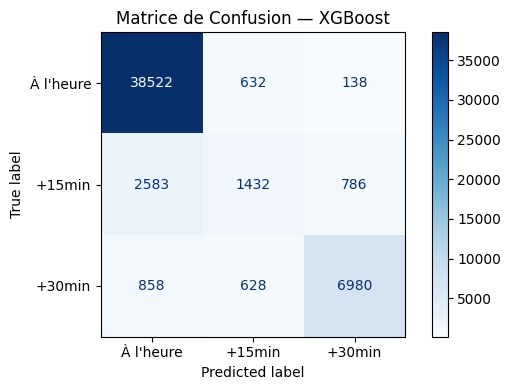

 Faux négatifs (retards non anticipés) : 3441 / 13267 (25.9%)
 ROC-AUC : 0.9307


In [ ]:
print(" Entraînement XGBoost...")

xgb = XGBClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss',
    verbosity=0
)
xgb.fit(X_train, y_train)

print(" Entraînement terminé !")
evaluate_model("XGBoost", xgb, X_test, y_test)

## 9. Optimisation — GridSearchCV

On utilise GridSearchCV pour trouver automatiquement les meilleurs
hyperparamètres de XGBoost. On teste 16 combinaisons (2x2x2x2)
avec une validation croisée à 3 folds = 48 entraînements au total.

Paramètres testés :
- n_estimators : [100, 200]
- max_depth : [4, 6]
- learning_rate : [0.05, 0.1]
- subsample : [0.8, 1.0]

Meilleurs paramètres trouvés :
learning_rate=0.1, max_depth=4, n_estimators=200, subsample=0.8

Observation : le tuning n'améliore pas significativement les résultats
car XGBoost était déjà bien configuré avec les paramètres par défaut.

 GridSearchCV en cours (10-20 min)...
On cherche les meilleurs paramètres automatiquement...

GridSearch sur 30000 lignes, 16 combinaisons x 3 folds...

Fitting 3 folds for each of 16 candidates, totalling 48 fits

 Meilleurs paramètres : {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}
 Meilleur score CV   : 0.7249

 Réentraînement sur tout le train avec les meilleurs paramètres...
 Terminé !

 MODÈLE : XGBoost (tuned)
               precision    recall  f1-score   support

    À l'heure       0.91      0.98      0.95     39292
Retard +15min       0.53      0.28      0.37      4801
Retard +30min       0.89      0.81      0.85      8466

     accuracy                           0.89     52559
    macro avg       0.78      0.69      0.72     52559
 weighted avg       0.87      0.89      0.88     52559



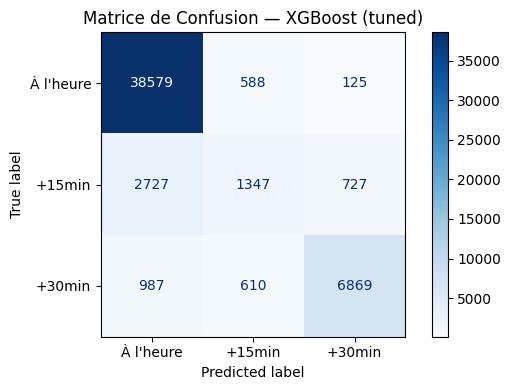

 Faux négatifs (retards non anticipés) : 3714 / 13267 (28.0%)
 ROC-AUC : 0.9256


In [ ]:
print(" GridSearchCV en cours (10-20 min)...")
print("On cherche les meilleurs paramètres automatiquement...\n")

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0]
}

# Sous-échantillon pour aller plus vite
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train,
    train_size=30000,
    random_state=42,
    stratify=y_train
)

print(f"GridSearch sur {X_tune.shape[0]} lignes, {len(param_grid['n_estimators']) * len(param_grid['max_depth']) * len(param_grid['learning_rate']) * len(param_grid['subsample'])} combinaisons x 3 folds...\n")

grid = GridSearchCV(
    XGBClassifier(random_state=42, verbosity=0, eval_metric='mlogloss'),
    param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)
grid.fit(X_tune, y_tune)

print(f"\n Meilleurs paramètres : {grid.best_params_}")
print(f" Meilleur score CV   : {grid.best_score_:.4f}")

# Réentraîner sur tout le train avec les meilleurs paramètres
print("\n Réentraînement sur tout le train avec les meilleurs paramètres...")
best_xgb = XGBClassifier(**grid.best_params_, random_state=42, verbosity=0, eval_metric='mlogloss')
best_xgb.fit(X_train, y_train)

print(" Terminé !")
evaluate_model("XGBoost (tuned)", best_xgb, X_test, y_test)

## 10. Courbes ROC — Comparaison des modèles

Les courbes ROC montrent la performance de chaque modèle à tous les seuils
de décision. Plus la courbe est en haut à gauche, meilleur est le modèle.
L'AUC (Area Under Curve) résume la performance en un seul chiffre entre 0 et 1.

On trace les courbes pour les 3 classes séparément (One vs Rest).

 Génération des courbes ROC...


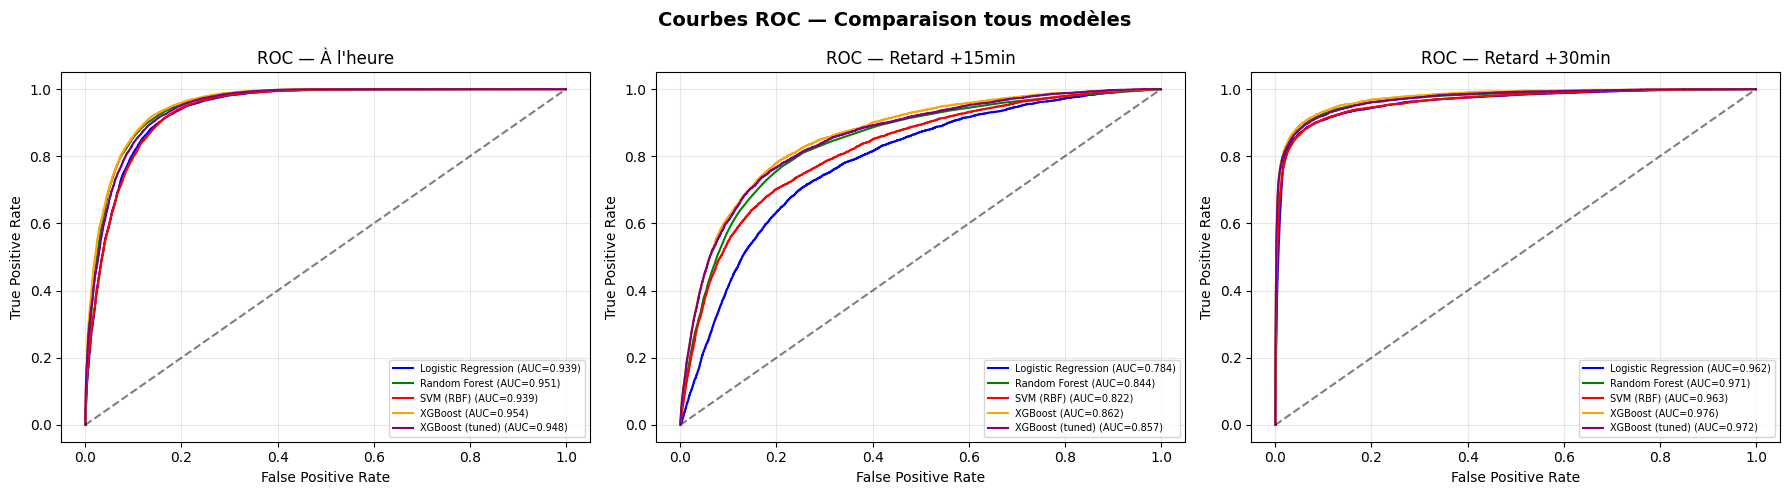

 Graphique sauvegardé : roc_curves.png


In [ ]:
print(" Génération des courbes ROC...")

models_for_plot = {
    'Logistic Regression': (lr, X_test_scaled),
    'Random Forest':       (rf, X_test),
    'SVM (RBF)':           (svm, X_test_scaled),
    'XGBoost':             (xgb, X_test),
    'XGBoost (tuned)':     (best_xgb, X_test)
}

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
class_names = ["À l'heure", "Retard +15min", "Retard +30min"]
colors = ['blue', 'green', 'red', 'orange', 'purple']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, class_name in enumerate(class_names):
    ax = axes[i]
    for (model_name, (model, X_t)), color in zip(models_for_plot.items(), colors):
        y_proba = model.predict_proba(X_t)
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        auc = roc_auc_score(y_test_bin[:, i], y_proba[:, i])
        ax.plot(fpr, tpr, label=f"{model_name} (AUC={auc:.3f})", color=color)
    ax.plot([0,1],[0,1],'k--', alpha=0.5)
    ax.set_title(f"ROC — {class_name}")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle("Courbes ROC — Comparaison tous modèles", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()
print(" Graphique sauvegardé : roc_curves.png")

## 11. Tableau comparatif final

Récapitulatif des performances de tous les modèles sur les métriques clés :
- Accuracy : proportion de bonnes prédictions
- ROC-AUC : performance globale du modèle
- Faux Négatifs : vols retardés non détectés (métrique critique )

 TABLEAU COMPARATIF FINAL
                     Accuracy  ROC-AUC  Faux Négatifs  Taux FN %
Logistic Regression    0.8154   0.8950         1531.0       11.5
Random Forest          0.8867   0.9220         4245.0       32.0
SVM (RBF)              0.8298   0.9078         1875.0       14.1
XGBoost                0.8930   0.9307         3441.0       25.9
XGBoost (tuned)        0.8903   0.9256         3714.0       28.0


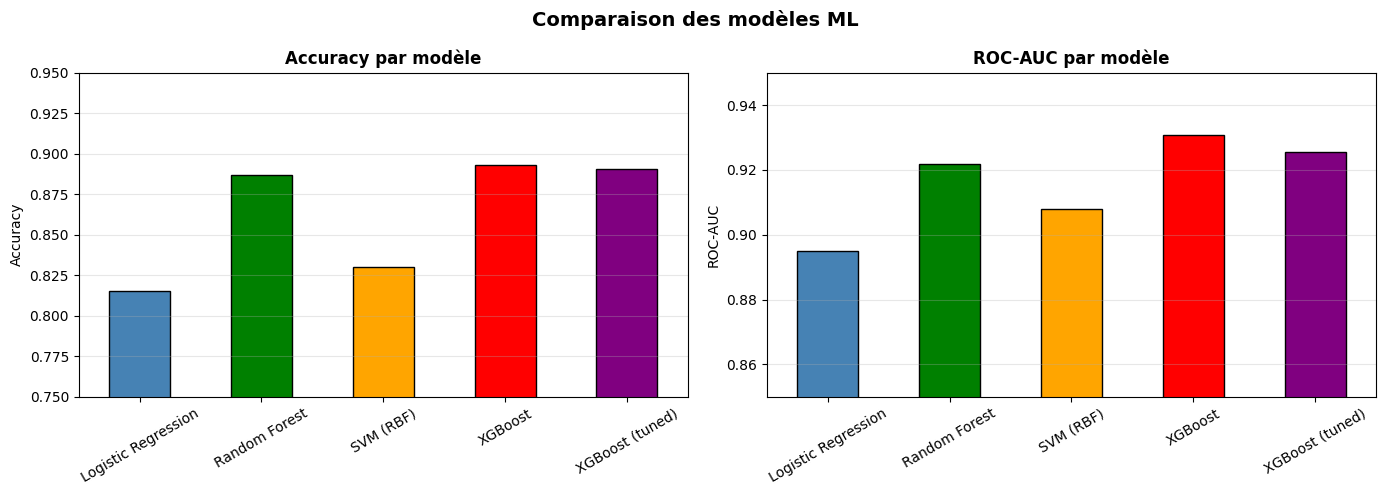

 Graphique sauvegardé : model_comparison.png


In [ ]:
print(" TABLEAU COMPARATIF FINAL")
print("="*60)

comparison = pd.DataFrame(results).T
print(comparison.to_string())

# Graphique comparatif
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
comparison['Accuracy'].plot(
    kind='bar', ax=axes[0],
    color=['steelblue','green','orange','red','purple'],
    edgecolor='black'
)
axes[0].set_title("Accuracy par modèle", fontweight='bold')
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.75, 0.95)
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', alpha=0.3)

# ROC-AUC
comparison['ROC-AUC'].plot(
    kind='bar', ax=axes[1],
    color=['steelblue','green','orange','red','purple'],
    edgecolor='black'
)
axes[1].set_title("ROC-AUC par modèle", fontweight='bold')
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0.85, 0.95)
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle("Comparaison des modèles ML", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()
print(" Graphique sauvegardé : model_comparison.png")

## 12. Courbes Precision-Recall

La courbe Precision-Recall est particulièrement utile quand les classes
sont déséquilibrées (notre cas : classe 1 = 9% seulement).

- **Precision** : parmi les vols prédit retardés, combien l'étaient vraiment ?
- **Recall** : parmi les vols vraiment retardés, combien a-t-on détectés ?

L'Average Precision (AP) résume la courbe en un seul score.

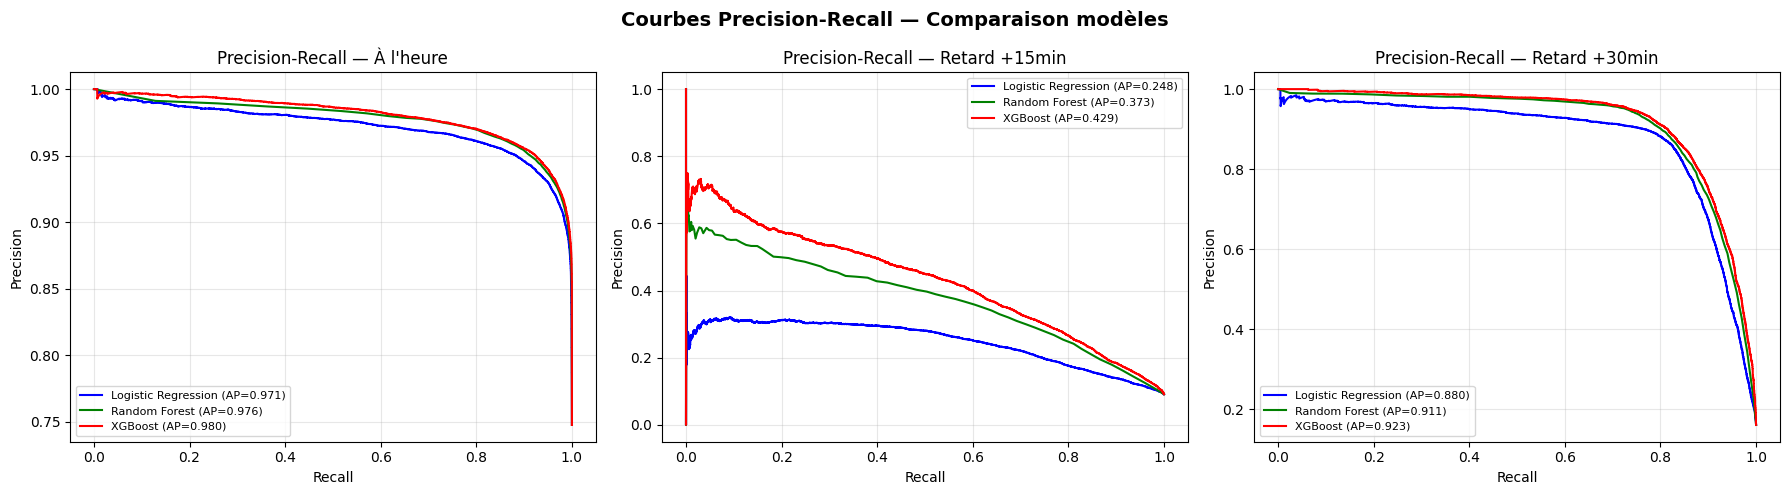

 Graphique sauvegardé : precision_recall_curves.png


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
class_names = ["À l'heure", "Retard +15min", "Retard +30min"]

models_pr = {
    'Logistic Regression': (lr, X_test_scaled),
    'Random Forest':       (rf, X_test),
    'XGBoost':             (xgb, X_test)
}

colors = ['blue', 'green', 'red']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, class_name in enumerate(class_names):
    ax = axes[i]
    for (model_name, (model, X_t)), color in zip(models_pr.items(), colors):
        y_proba = model.predict_proba(X_t)
        precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_proba[:, i])
        ap = average_precision_score(y_test_bin[:, i], y_proba[:, i])
        ax.plot(recall, precision, label=f"{model_name} (AP={ap:.3f})", color=color)
    ax.set_title(f"Precision-Recall — {class_name}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle("Courbes Precision-Recall — Comparaison modèles", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("precision_recall_curves.png", dpi=150)
plt.show()
print(" Graphique sauvegardé : precision_recall_curves.png")

## 13. Conclusion

### Meilleur modèle : XGBoost
- ROC-AUC : 0.9307 (le plus élevé)
- Accuracy : 0.893
- Meilleur sur les courbes Precision-Recall pour toutes les classes

### Points clés
- DEPARTURE_DELAY est la feature la plus importante (44%) — logique car
  un retard au départ annonce souvent un retard à l'arrivée
- La classe +15min est la plus difficile à prédire (sous-représentée à 9%)
- Le GridSearchCV n'a pas amélioré XGBoost — il était déjà bien paramétré

### Limites
- SVM entraîné sur seulement 15 000 lignes (contrainte de performance)
- Le dataset est déséquilibré — la classe 1 reste difficile à détecter

### Fichiers produits pour le Binôme 3
- best_model_xgb.pkl : meilleur modèle sauvegardé
- scaler.pkl : normalisation pour nouvelles données
- roc_curves.png, precision_recall_curves.png, model_comparison.png

In [ ]:
import joblib

# Sauvegarder le meilleur modèle
joblib.dump(xgb, 'best_model_xgb.pkl')
joblib.dump(scaler, 'scaler.pkl')

print(" Modèles sauvegardés :")
print("   → best_model_xgb.pkl  (pour le binôme 3 et le pipeline)")
print("   → scaler.pkl          (pour normaliser les nouvelles données)")

# Télécharger les fichiers
from google.colab import files
files.download('best_model_xgb.pkl')
files.download('scaler.pkl')
files.download('roc_curves.png')
files.download('model_comparison.png')

 Modèles sauvegardés :
   → best_model_xgb.pkl  (pour le binôme 3 et le pipeline)
   → scaler.pkl          (pour normaliser les nouvelles données)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>